<a href="https://colab.research.google.com/github/atempvisit/learning-deep_learning/blob/main/Module_18_Data_Scaling%2C_Standardization_and_Normalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('Social_Network_Ads.csv')
df = df.iloc[:, 2:]  # slicing columns

In [5]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [7]:
X = df.iloc[:, 0:2].values
y = df.iloc[:, -1].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# convert to tensor

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

In [9]:
# Model

class Model(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(2, 128)
    self.relu = nn.ReLU()
    self.fc2 = nn.Linear(128, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    x = self.fc1(x)
    x = self.relu(x)
    x = self.fc2(x)
    x = self.sigmoid(x)

    return x

In [10]:
model = Model()

In [11]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [13]:
epochs = 100
val_acc_list = []

In [15]:
for epoch in range(epochs):
  # forward pass
  outputs = model(X_train)
  loss = criterion(outputs, y_train)

  # backward pass
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # validation

  with torch.no_grad():
    outputs = model(X_test)
    predicted = (outputs >= 0.5).float()
    accuracy = (predicted == y_test).float().mean()
    val_acc_list.append(accuracy.item())

  if (epoch+1) % 10 == 0:
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}, Validation Accuracy: {accuracy.item():.4f}')

Epoch [10/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [20/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [30/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [40/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [50/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [60/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [70/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [80/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [90/100], Loss: 64.0625, Validation Accuracy: 0.3500
Epoch [100/100], Loss: 64.0625, Validation Accuracy: 0.3500


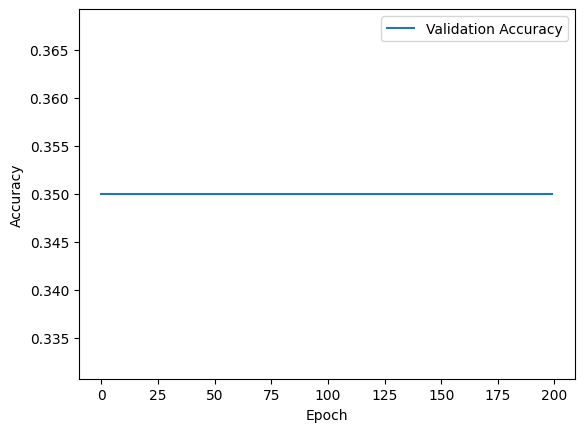

In [16]:
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.numpy())
X_test_scaled = scaler.transform(X_test.numpy())

X_train_scaled = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_scaled = torch.tensor(X_test_scaled, dtype=torch.float32)

model = Model()
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


epochs = 100
val_acc_list = []

for epoch in range(epochs):
  # forward pass
  outputs = model(X_train_scaled)
  loss = criterion(outputs, y_train)

  # backward pass
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # validation

  with torch.no_grad():
    outputs = model(X_test_scaled)
    predicted = (outputs >= 0.5).float()
    accuracy = (predicted == y_test).float().mean()
    val_acc_list.append(accuracy.item())

  if (epoch+1) % 10 == 0:
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}, Validation Accuracy: {accuracy.item():.4f}')

Epoch [10/100], Loss: 0.6170, Validation Accuracy: 0.8375
Epoch [20/100], Loss: 0.5521, Validation Accuracy: 0.8875
Epoch [30/100], Loss: 0.5027, Validation Accuracy: 0.8625
Epoch [40/100], Loss: 0.4647, Validation Accuracy: 0.8750
Epoch [50/100], Loss: 0.4348, Validation Accuracy: 0.8750
Epoch [60/100], Loss: 0.4106, Validation Accuracy: 0.8875
Epoch [70/100], Loss: 0.3904, Validation Accuracy: 0.9000
Epoch [80/100], Loss: 0.3733, Validation Accuracy: 0.8875
Epoch [90/100], Loss: 0.3585, Validation Accuracy: 0.9125
Epoch [100/100], Loss: 0.3457, Validation Accuracy: 0.9125


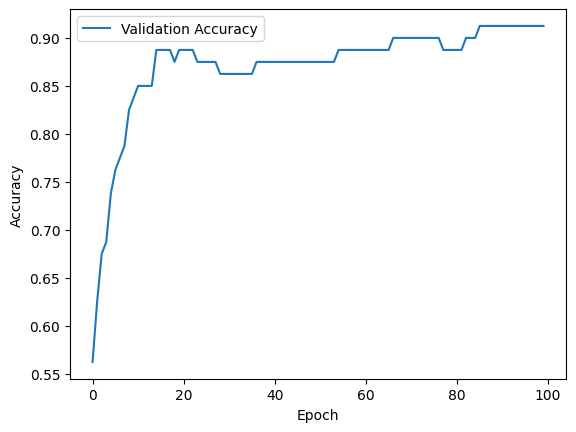

In [20]:
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
#